# Heart Disease Risk Modelling — Phase 2: Regularised MLP vs Bayesian Network
**Deep Learning · Project 15** &nbsp;|&nbsp; Hand-specified independence structure → learned feature interactions

| Student | Enrollment no. |
|---|---|
| Aaryan Yadav | 2401010011 |
| Shivam Mishra | 2401010442 |
| Satyam Kumar | 2401010429 |
| Himank Kaushik | 2401010187 |
| Mohammed Yaseen | 2401010281 |

> **Scope.** Phase 1 (`01_phase1_eda_and_classical_models.ipynb`) built the AML baseline: a domain-informed Bayesian network (pgmpy), Naive Bayes and classical references. This notebook is **Phase 2 (Deep Learning)**: a regularised feed-forward neural network (MLP, PyTorch) on scaled numeric and one-hot categorical inputs, evaluated on the **same 25 saved cross-validation splits**, with ROC AUC, PR AUC, sensitivity, specificity and calibration, SHAP explanations, and an interpretable probability comparison against the Bayesian network.
>
> **Disclaimer.** This is a prediction exercise on a historical research dataset, *not* clinical decision support. Predicted probabilities must not be read as medical recommendations.

**Notebook map:** 1 Setup & the Phase 1 gap · 2 MLP design · 3 Nested cross-validation · 4 Results · 5 Calibration · 6 Paired comparisons · 7 Ablations (binned inputs, no ca/thal) · 8 BN vs MLP probabilities, patient by patient · 9 Explanations: SHAP vs BN weight of evidence · 10 Cost · 11 Findings and limitations

In [1]:
%matplotlib inline
import sys, time, warnings
warnings.filterwarnings("ignore", category=FutureWarning); warnings.filterwarnings("ignore", category=UserWarning)
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from data import *; from bayes import *; from classical import *; from evaluate import *; from metrics import *
from mlp import MLP, GRID, MAX_EPOCHS, LR, grid
from explain import mlp_shap
RES = Path("../results"); FIG = RES / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED, K, R, B = 2026, 5, 5, 500                       # identical to Phase 1
POS, NEG, BLUE, AMBER, GREY, PURPLE = "#e63946", "#2a9d8f", "#2a6f97", "#d98e04", "#6c757d", "#7b2cbf"
COL = {"Naive Bayes": AMBER, "Bayesian net": BLUE, "LogReg (cont.)": GREY, "LogReg (disc.)": "#adb5bd", "Random forest": "#2a9d8f", "MLP": PURPLE, "MLP (binned)": "#c77dff"}
def save(name): plt.tight_layout(); plt.savefig(FIG / name, dpi=150); plt.show()
print("torch", torch.__version__)

torch 2.15.0


## 1. Setup and the gap Phase 2 has to address
Same data, same binary target (`num > 0`, 139 / 303 positive) and the **same 25 split indices** as Phase 1 (5-fold × 5 repeats, seed 2026). The cell below rebuilds the splits and checks them against the saved Phase 1 manifest, then reloads the Phase 1 out-of-fold (OOF) predictions so the classical models are compared on exactly the predictions reported in Phase 1, not on a re-run.

**The gap (from the project brief and the Phase 1 results).** The Bayesian network needs a fixed graph and coarse bins. Phase 1 found that (i) ranking was similar across models (AUC ≈ 0.90–0.91), but (ii) the BN and Naive Bayes were clearly **over-confident** (calibration slope ≈ 0.5), while logistic regression was close to calibrated. The brief's hypothesis is that a fixed structure and discretisation miss continuous and nonlinear interactions among age, heart rate, blood pressure and symptoms. Phase 2 tests whether a model that *learns* interactions from continuous inputs (i) ranks better and (ii) gives better probabilities.

In [2]:
df = load(); y = df.target.values; Xr = df[FEATURES]; Xd = discretize(df)
splits = list(RepeatedStratifiedKFold(n_splits=K, n_repeats=R, random_state=SEED).split(Xr, y))
manifest = pd.read_csv(RES / "cv_test_assignments.csv")
assert all(set(manifest.loc[manifest.split == s, "patient"]) == set(te) for s, (_, te) in enumerate(splits)), "splits differ from Phase 1"
print("splits identical to the saved Phase 1 manifest:", len(splits), "splits")

p1 = pd.read_csv(RES / "phase1_oof_predictions.csv.gz")
def as_result(oof):
    # rebuild the run_cv output (OOF matrix + per-fold AUC) from saved predictions
    return dict(oof=oof, fold_auc=np.array([roc_auc_score(y[te], oof[s // K, te]) for s, (_, te) in enumerate(splits)]))
results = {m: as_result(g.sort_values(["repeat", "patient"]).p.to_numpy().reshape(R, len(y))) for m, g in p1.groupby("model", sort=False)}
print("Phase 1 models reloaded:", list(results))
display(pd.read_csv(RES / "phase1_baselines_for_phase2.csv").set_index("model"))

splits identical to the saved Phase 1 manifest: 25 splits
Phase 1 models reloaded: ['Prior only', 'Naive Bayes', 'Bayesian net', 'LogReg (disc.)', 'LogReg (cont.)', 'Random forest']


,ROC AUC,PR AUC,Sensitivity,Specificity,Brier,ECE,Cal. slope
model,,,,,,,
Naive Bayes,0.908,0.904,0.791,0.888,0.126,0.087,0.511
Bayesian net,0.896,0.882,0.778,0.851,0.139,0.086,0.487
LogReg (disc.),0.907,0.898,0.809,0.888,0.118,0.050,0.987
LogReg (cont.),0.911,0.905,0.804,0.889,0.116,0.047,0.983
Random forest,0.908,0.901,0.787,0.855,0.125,0.055,1.421


## 2. MLP design
**Inputs.** Exactly the Phase 1 logistic-regression preprocessor: the 5 numeric variables are median-imputed and standardised, the 8 categorical variables are mode-imputed and one-hot encoded using the full UCI state lists (28 input columns). The preprocessor is fitted **inside each training fold** (and again inside each inner tuning fold), so nothing from a held-out fold leaks into training.

**Network.** `Linear → ReLU → Dropout` block(s) and a single output logit trained with binary cross-entropy (log loss). Full-batch AdamW (learning rate 3e-3).

**Regularisation** (303 patients is tiny for a neural network): L2 weight decay, dropout, a small architecture, early stopping, and averaging the logits of 5 random initialisations (seeds) in the final model.

**Nested tuning.** Inside every outer training fold (~242 rows), a stratified 3-fold *inner* CV evaluates each of the 12 configurations below for up to 300 epochs and records the validation log loss after every epoch. The configuration **and** the number of epochs with the lowest mean inner log loss are chosen; the network is then refit on the whole outer training fold for that many epochs. The outer held-out fold is never touched during tuning, so the reported numbers are not optimistically selected. (Phase 1's classical models used fixed settings; the MLP is given a fair tuning budget because, unlike logistic regression, it has no sensible default.) The grid was fixed before any outer results were seen. Log loss is the selection criterion because it rewards good probabilities, not only good ranking.

In [3]:
print("search grid:", GRID, "| configurations:", len(grid()), "| max epochs:", MAX_EPOCHS, "| learning rate:", LR)
demo = MLP(tune=False, epochs=1, n_seeds=1).fit(Xr, y)
print("input columns after preprocessing:", demo.pre.transform(Xr.head(1)).shape[1])
for cfg in [{"hidden": (16,), "weight_decay": 0, "dropout": 0}, {"hidden": (32, 16), "weight_decay": 0, "dropout": 0}]:
    print(f"hidden={cfg['hidden']}: {MLP(tune=False, config=cfg, epochs=1, n_seeds=1).fit(Xr, y).n_params()} trainable parameters")

search grid: {'hidden': [(16,), (32, 16)], 'weight_decay': [0.001, 0.01, 0.1], 'dropout': [0.1, 0.3]} | configurations: 12 | max epochs: 300 | learning rate: 0.003
input columns after preprocessing: 28
hidden=(16,): 481 trainable parameters
hidden=(32, 16): 1473 trainable parameters


## 3. Nested cross-validation of the MLP
Each outer split `s` uses seed `s` (as the Phase 1 forest did). Predictions are stored for every patient once per repeat. This takes about a minute and a half on a laptop CPU.

In [4]:
def run_mlp(name, X, **kw):
    fitted = []
    def make(s):
        m = MLP(seed=s, **kw); fitted.append(m); return m
    t = time.time(); r = run_cv(make, X, y, splits, K); r["seconds"] = time.time() - t; r["models"] = fitted
    print(f"{name:<22} mean ROC AUC over repeats = {np.mean([roc_auc_score(y, o) for o in r['oof']]):.3f}  ({r['seconds']:.0f}s)")
    return r

mlp_runs = {"MLP": run_mlp("MLP", Xr),
            "MLP (binned)": run_mlp("MLP (binned)", Xd, mode="discretized")}
NO_TEST = [f for f in FEATURES if f not in ("ca", "thal")]
mlp_noct = run_mlp("MLP (no ca/thal)", Xr, features=NO_TEST)

MLP                    mean ROC AUC over repeats = 0.911  (65s)
MLP (binned)           mean ROC AUC over repeats = 0.911  (63s)
MLP (no ca/thal)       mean ROC AUC over repeats = 0.868  (64s)


In [5]:
hp = pd.DataFrame([{"split": s, "repeat": s // K, "fold": s % K, "hidden": str(m.config["hidden"]), "weight_decay": m.config["weight_decay"],
                    "dropout": m.config["dropout"], "epochs": m.epochs, "inner log loss": m.inner_logloss_}
                   for s, m in enumerate(mlp_runs["MLP"]["models"])])
hp.to_csv(RES / "phase2_mlp_hparams.csv", index=False)
print("Chosen configuration across the 25 outer training folds:")
display(hp.groupby(["hidden", "weight_decay", "dropout"]).size().rename("times chosen").to_frame())
print(f"chosen epochs: median {hp.epochs.median():.0f}, range {hp.epochs.min()}–{hp.epochs.max()}")
pd.concat([pd.DataFrame({"model": n, "repeat": r, "patient": np.arange(len(y)), "y": y, "p": d["oof"][r]})
           for n, d in {**mlp_runs, "MLP (no ca/thal)": mlp_noct}.items() for r in range(R)]).to_csv(RES / "phase2_oof_predictions.csv.gz", index=False)

Chosen configuration across the 25 outer training folds:


times chosen
hidden   weight_decay dropout              
(16,)    0.001        0.1                 2
                      0.3                 4
         0.010        0.1                 2
                      0.3                 1
         0.100        0.1                 7
                      0.3                 6
(32, 16) 0.001        0.3                 2
         0.010        0.3                 1

chosen epochs: median 73, range 38–98


**Reading the tuning table.** If a single small hidden layer is chosen almost everywhere and the epoch count is modest, the inner CV is consistently favouring a heavily regularised, nearly-linear network. That is itself evidence about the data: there is not much nonlinear structure for a network to exploit at n = 303.

## 4. Results on the shared 25 splits
Metrics are computed per repeat on all 303 OOF predictions and averaged over the 5 repeats; 95% intervals come from 500 patient-bootstrap resamples shared by every model (identical to Phase 1, so the Phase 1 rows reproduce the Phase 1 table exactly; this is asserted below). PR AUC is average precision; sensitivity and specificity use a 0.5 threshold.

In [6]:
results.update({k: {kk: v[kk] for kk in ("oof", "fold_auc")} for k, v in mlp_runs.items()})
M, bv = summarize(results, y, B=B, seed=SEED); M.to_csv(RES / "phase2_metrics.csv", index=False); Mi = M.set_index("model")
old = pd.read_csv(RES / "phase1_metrics.csv").set_index("model").drop(index="Prior only")   # constant predictor: ECE bins depend on tie order, so it is skipped
assert np.allclose(Mi.loc[old.index, old.columns].astype(float).values, old.values.astype(float), equal_nan=True, atol=1e-10), "Phase 1 rows changed"
print("Phase 1 model rows reproduce phase1_metrics.csv exactly (to 1e-10).")
show = M.copy()
for k in ["ROC AUC", "PR AUC", "Brier"]:
    show[k + " [95% CI]"] = show.apply(lambda r: f"{r[k]:.3f} [{r[k+' lo']:.3f}, {r[k+' hi']:.3f}]" if pd.notna(r.get(k + " lo")) else f"{r[k]:.3f}", axis=1)
display(show[["model", "ROC AUC [95% CI]", "PR AUC [95% CI]", "Sensitivity", "Specificity", "Brier [95% CI]", "ECE", "Log loss", "Cal. slope", "Cal. intercept"]].round(3).set_index("model"))

Phase 1 model rows reproduce phase1_metrics.csv exactly (to 1e-10).


,ROC AUC [95% CI],PR AUC [95% CI],Sensitivity,Specificity,Brier [95% CI],ECE,Log loss,Cal. slope,Cal. intercept
model,,,,,,,,,
Prior only,0.495,0.456,0.000,1.000,0.248,0.064,NaN,NaN,NaN
Naive Bayes,"0.908 [0.874, 0.939]","0.904 [0.858, 0.940]",0.791,0.888,"0.126 [0.096, 0.155]",0.087,0.456,0.511,-0.006
Bayesian net,"0.896 [0.861, 0.927]","0.882 [0.833, 0.926]",0.778,0.851,"0.139 [0.107, 0.167]",0.086,0.494,0.487,-0.037
LogReg (disc.),"0.907 [0.870, 0.938]","0.898 [0.845, 0.938]",0.809,0.888,"0.118 [0.096, 0.144]",0.050,0.380,0.987,0.023
LogReg (cont.),"0.911 [0.875, 0.941]","0.905 [0.858, 0.941]",0.804,0.889,"0.116 [0.094, 0.141]",0.047,0.373,0.983,0.008
Random forest,"0.908 [0.869, 0.938]","0.901 [0.858, 0.937]",0.787,0.855,"0.125 [0.106, 0.146]",0.055,0.394,1.421,0.074
MLP,"0.911 [0.876, 0.942]","0.901 [0.855, 0.941]",0.810,0.876,"0.117 [0.093, 0.141]",0.044,0.375,0.996,-0.004
MLP (binned),"0.911 [0.875, 0.942]","0.904 [0.852, 0.942]",0.804,0.889,"0.115 [0.093, 0.139]",0.044,0.373,1.066,0.047


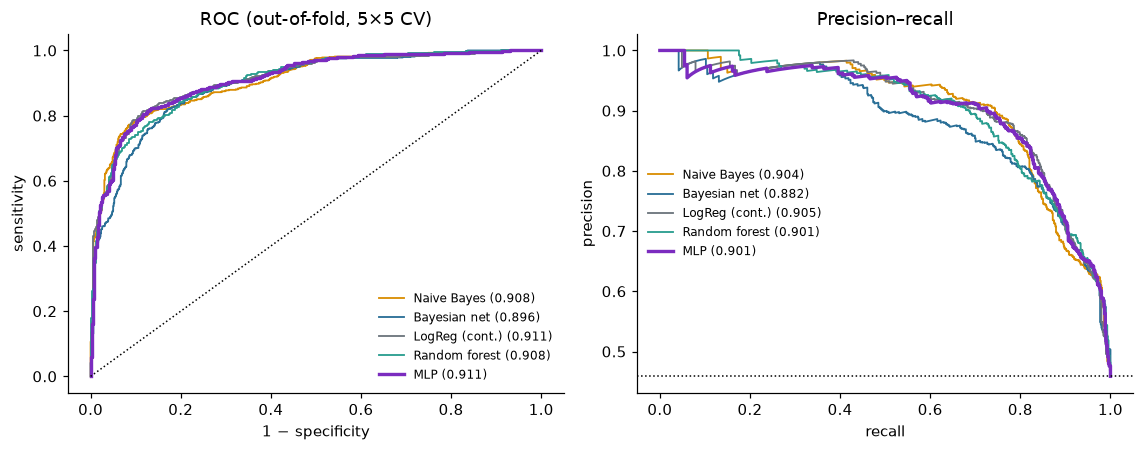

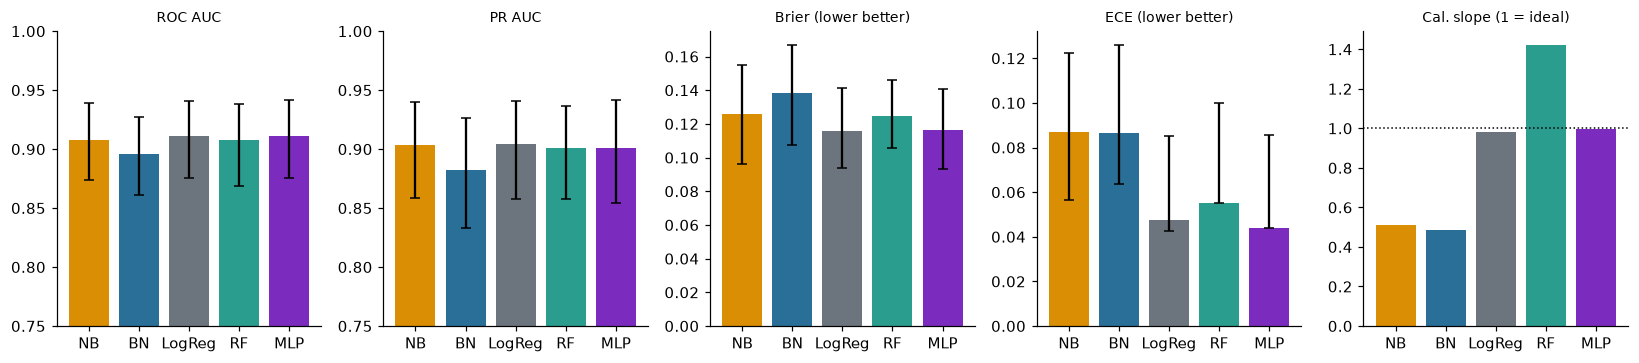

In [7]:
SHOW = ["Naive Bayes", "Bayesian net", "LogReg (cont.)", "Random forest", "MLP"]
pool = lambda m: (np.tile(y, R), results[m]["oof"].ravel())
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2))
for m in SHOW:
    yy, pp = pool(m); f, t, _ = roc_curve(yy, pp); ax[0].plot(f, t, color=COL[m], lw=2.2 if m == "MLP" else 1.2, label=f"{m} ({Mi.loc[m, 'ROC AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(yy, pp); ax[1].plot(rc, pr, color=COL[m], lw=2.2 if m == "MLP" else 1.2, label=f"{m} ({Mi.loc[m, 'PR AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(xlabel="1 − specificity", ylabel="sensitivity", title="ROC (out-of-fold, 5×5 CV)")
ax[1].axhline(y.mean(), color="k", ls=":", lw=1); ax[1].set(xlabel="recall", ylabel="precision", title="Precision–recall")
for a in ax: a.legend(frameon=False, fontsize=8)
save("fig_p2_roc_pr.png")
fig, ax = plt.subplots(1, 5, figsize=(15, 3.4))
for a, k in zip(ax, ["ROC AUC", "PR AUC", "Brier", "ECE", "Cal. slope"]):
    d = Mi.loc[SHOW]; err = None
    if k + " lo" in d: err = [(d[k] - d[k + " lo"]).clip(lower=0), (d[k + " hi"] - d[k]).clip(lower=0)]
    a.bar(range(len(SHOW)), d[k], color=[COL[m] for m in SHOW], yerr=err, capsize=3)
    a.set_xticks(range(len(SHOW))); a.set_xticklabels(["NB", "BN", "LogReg", "RF", "MLP"]); a.set_title(k + (" (lower better)" if k in ("Brier", "ECE") else " (1 = ideal)" if k == "Cal. slope" else ""), fontsize=9)
    if "AUC" in k: a.set_ylim(.75, 1)
    if k == "Cal. slope": a.axhline(1, color="k", ls=":", lw=1)
save("fig_p2_metrics.png")

## 5. Calibration: does "0.8" mean 8 in 10?
Reliability curves pool the 5 repeats (descriptive only; the 1,515 points come from 303 patients). Calibration slope < 1 means predictions are too extreme (over-confident); > 1 means too timid. The histogram under each curve shows how the model spreads its probabilities.

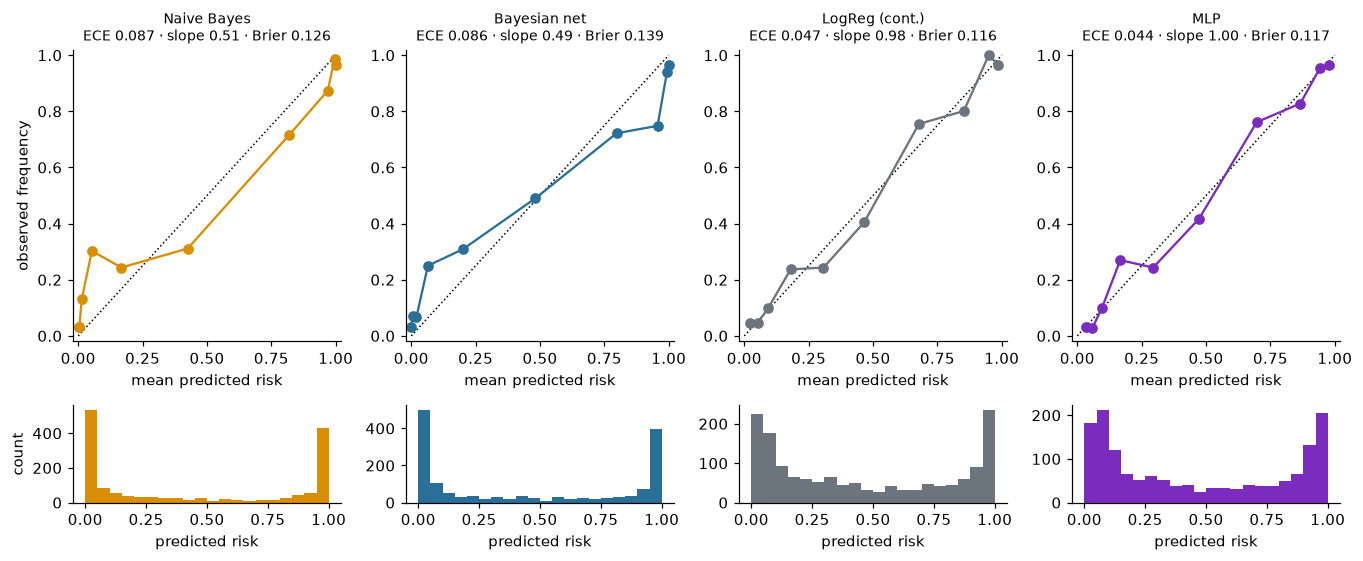

share of OOF predictions below 0.05 or above 0.95: {'Naive Bayes': np.float64(0.635), 'Bayesian net': np.float64(0.59), 'LogReg (cont.)': np.float64(0.303), 'MLP': np.float64(0.255)}


In [8]:
CAL = ["Naive Bayes", "Bayesian net", "LogReg (cont.)", "MLP"]
fig, ax = plt.subplots(2, 4, figsize=(12.5, 5.2), gridspec_kw={"height_ratios": [3, 1]})
for j, m in enumerate(CAL):
    yy, pp = pool(m); ch = np.array_split(np.argsort(pp), 10)
    ax[0, j].plot([0, 1], [0, 1], "k:", lw=1); ax[0, j].plot([pp[c].mean() for c in ch], [yy[c].mean() for c in ch], "o-", color=COL[m])
    ax[0, j].set(title=f"{m}\nECE {Mi.loc[m,'ECE']:.3f} · slope {Mi.loc[m,'Cal. slope']:.2f} · Brier {Mi.loc[m,'Brier']:.3f}", xlim=(-.02, 1.02), ylim=(-.02, 1.02),
                 xlabel="mean predicted risk", ylabel="observed frequency" if j == 0 else ""); ax[0, j].title.set_fontsize(9)
    ax[1, j].hist(pp, bins=20, range=(0, 1), color=COL[m]); ax[1, j].set(xlabel="predicted risk", ylabel="count" if j == 0 else "")
save("fig_p2_calibration.png")
share = lambda m: np.mean((results[m]["oof"] < .05) | (results[m]["oof"] > .95))
print("share of OOF predictions below 0.05 or above 0.95:", {m: round(share(m), 3) for m in CAL})

## 6. Exploratory paired comparisons
Same procedure as Phase 1: point difference = difference of the OOF metrics; interval = paired patient bootstrap; *p* = Nadeau–Bengio corrected resampled *t*-test on the 25 fold AUCs. These are exploratory, with no multiplicity correction. A non-significant difference is **not** evidence that two models are equivalent.

In [9]:
pairs = [("MLP", "Bayesian net"), ("MLP", "Naive Bayes"), ("MLP", "LogReg (cont.)"), ("MLP", "Random forest"),
         ("MLP (binned)", "Bayesian net"), ("MLP", "MLP (binned)")]
PC = paired(results, bv, pairs, K, y=y); PC.to_csv(RES / "phase2_paired.csv", index=False)
display(PC.round(3))

,A,B,metric,mean diff (A-B),lo,hi,corrected t,corrected p
0,MLP,Bayesian net,ROC AUC,0.015,-0.001,0.031,1.542,0.136
1,MLP,Bayesian net,PR AUC,0.019,0.001,0.036,NaN,NaN
2,MLP,Bayesian net,Brier,-0.022,-0.036,-0.007,NaN,NaN
3,MLP,Naive Bayes,ROC AUC,0.003,-0.005,0.014,0.844,0.407
4,MLP,Naive Bayes,PR AUC,-0.003,-0.015,0.010,NaN,NaN
5,MLP,Naive Bayes,Brier,-0.009,-0.021,0.001,NaN,NaN
6,MLP,LogReg (cont.),ROC AUC,0.000,-0.005,0.007,0.219,0.829
7,MLP,LogReg (cont.),PR AUC,-0.004,-0.010,0.004,NaN,NaN
8,MLP,LogReg (cont.),Brier,0.001,-0.004,0.005,NaN,NaN
9,MLP,Random forest,ROC AUC,0.003,-0.007,0.015,0.737,0.468


**What each comparison isolates.**
- *MLP − Bayesian net* — the headline project comparison (learned interactions on continuous inputs vs hand-specified structure on bins).
- *MLP − LogReg (cont.)* — **the cleanest test of the gap's "nonlinear interactions" claim**: identical inputs and preprocessing; the only difference is whether hidden layers can learn interactions.
- *MLP (binned) − Bayesian net* — identical binned inputs; isolates "learned weights" vs "hand-specified graph + count-based CPDs".
- *MLP − MLP (binned)* — identical model; isolates what discretisation costs.

## 7. Ablation: without `ca` and `thal`
Same scenario as Phase 1 §7.2: drop the two diagnostic work-up variables (fluoroscopy vessel count and thallium scan). Phase 1 rows are read from the saved `phase1_scenarioB.csv` (same splits, same bootstrap seed).

In [10]:
MB2, _ = summarize({"MLP": mlp_noct}, y, B=B, seed=SEED)
MB = pd.concat([pd.read_csv(RES / "phase1_scenarioB.csv"), MB2]).set_index("model")
MB.reset_index().to_csv(RES / "phase2_scenarioB.csv", index=False)
cmp = MB[["ROC AUC", "ROC AUC lo", "ROC AUC hi", "PR AUC", "Brier", "ECE", "Cal. slope"]].copy()
cmp["ΔAUC vs all 13"] = MB["ROC AUC"] - Mi.loc[MB.index, "ROC AUC"]
display(cmp.round(3))

,ROC AUC,ROC AUC lo,ROC AUC hi,PR AUC,Brier,ECE,Cal. slope,ΔAUC vs all 13
model,,,,,,,,
Naive Bayes,0.866,0.825,0.906,0.858,0.158,0.108,0.524,-0.042
Bayesian net,0.846,0.805,0.884,0.815,0.170,0.107,0.488,-0.050
LogReg (cont.),0.872,0.830,0.909,0.860,0.144,0.046,0.945,-0.039
Random forest,0.862,0.820,0.900,0.852,0.151,0.061,1.209,-0.046
MLP,0.868,0.827,0.907,0.857,0.146,0.047,0.970,-0.043


## 8. Bayesian network vs MLP, patient by patient
The project deliverable asks for an *interpretable probability comparison*. Below, every patient's OOF probability from the BN is plotted against the MLP's (all 5 repeats). Points near the diagonal are patients the two models agree on; points far from it are where hand-specified structure and learned interactions disagree.

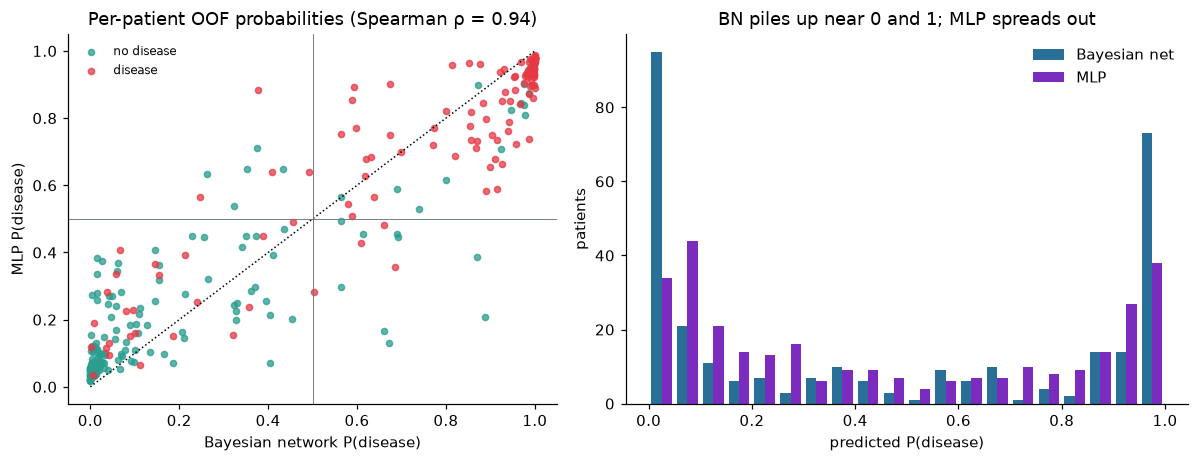

same side of 0.5 for 92.7% of patients; median |P_BN − P_MLP| = 0.065
confidently wrong patients (P>0.9 but healthy, or P<0.1 but diseased): {'Bayesian net': 21, 'MLP': 5}
Five largest BN–MLP disagreements:


,y,P_BN,P_MLP,loss_BN,loss_MLP,disagree,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal
139,0,0.887,0.207,2.185,0.232,0.681,51.0,125.0,245.0,166.0,2.4,1.0,3.0,1.0,2.0,0.0,2.0,0.0,3.0
179,0,0.672,0.132,1.114,0.141,0.540,53.0,130.0,246.0,173.0,0.0,1.0,3.0,1.0,2.0,0.0,1.0,3.0,3.0
111,1,0.378,0.884,0.973,0.124,0.506,56.0,125.0,249.0,144.0,1.2,1.0,4.0,1.0,2.0,1.0,2.0,1.0,3.0
258,0,0.660,0.165,1.080,0.180,0.495,70.0,156.0,245.0,143.0,0.0,1.0,2.0,0.0,2.0,0.0,1.0,0.0,3.0
150,0,0.871,0.387,2.044,0.489,0.484,52.0,152.0,298.0,178.0,1.2,1.0,1.0,1.0,0.0,0.0,2.0,0.0,7.0


In [11]:
pb, pm = results["Bayesian net"]["oof"].mean(0), results["MLP"]["oof"].mean(0)   # per-patient mean over repeats
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={"width_ratios": [1, 1.15]})
for t, c, l in [(0, NEG, "no disease"), (1, POS, "disease")]:
    ax[0].scatter(pb[y == t], pm[y == t], s=16, c=c, alpha=.75, label=l)
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].axhline(.5, color=GREY, lw=.6); ax[0].axvline(.5, color=GREY, lw=.6)
ax[0].set(xlabel="Bayesian network P(disease)", ylabel="MLP P(disease)", title=f"Per-patient OOF probabilities (Spearman ρ = {spearmanr(pb, pm)[0]:.2f})"); ax[0].legend(frameon=False, fontsize=8)
bins = np.linspace(0, 1, 21)
ax[1].hist([pb, pm], bins=bins, color=[BLUE, PURPLE], label=["Bayesian net", "MLP"]); ax[1].set(xlabel="predicted P(disease)", ylabel="patients", title="BN piles up near 0 and 1; MLP spreads out"); ax[1].legend(frameon=False)
save("fig_p2_bn_vs_mlp.png")
agree = np.mean((pb >= .5) == (pm >= .5))
print(f"same side of 0.5 for {agree:.1%} of patients; median |P_BN − P_MLP| = {np.median(np.abs(pb - pm)):.3f}")
ll = lambda p: -(y * np.log(np.clip(p, 1e-6, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-6, 1)))
wrong_conf = lambda p: np.sum(((p > .9) & (y == 0)) | ((p < .1) & (y == 1)))
print("confidently wrong patients (P>0.9 but healthy, or P<0.1 but diseased):", {"Bayesian net": int(wrong_conf(pb)), "MLP": int(wrong_conf(pm))})
D = pd.DataFrame({"y": y, "P_BN": pb, "P_MLP": pm, "loss_BN": ll(pb), "loss_MLP": ll(pm)})
D["disagree"] = (D.P_BN - D.P_MLP).abs()
print("Five largest BN–MLP disagreements:"); display(pd.concat([D, df[FEATURES]], axis=1).sort_values("disagree", ascending=False).head(5).round(3))

## 9. Explanations: SHAP for the MLP vs exact weight of evidence for the BN
Phase 1 decomposed the BN posterior log-odds exactly into a risk-factor term plus one log-likelihood-ratio per finding (for complete-evidence rows). For the MLP we use **Kernel SHAP on the 13 original variables in log-odds units** (the explained function includes preprocessing; background = 40 real training-fold rows). Both explanations are computed **out-of-fold on repeat 0**: each patient is explained by the model that did not see them. Kernel SHAP is additive by construction; the check below confirms SHAP values + base value reproduce the MLP logit.

Caveats: SHAP values are relative to an average background patient, whereas the BN risk-factor term is an absolute log-odds; so only the 8 *findings* are compared one-to-one. The BN uses age-adjusted peak heart rate (`apmhr`), the MLP raw `thalach`; they are paired as "heart rate". Explanations describe the models, not physiology or causation.

In [12]:
shap_rows, base = [], {}
for s, (tr, te) in enumerate(splits[:K]):
    m = mlp_runs["MLP"]["models"][s]
    assert np.allclose(m.predict_proba(Xr.iloc[te]), results["MLP"]["oof"][0, te]), "refit mismatch"
    S, b = mlp_shap(m, Xr.iloc[tr], Xr.iloc[te], seed=s); shap_rows.append(S)
    err = np.abs(S.sum(axis=1).values + b - m.decision_function(Xr.iloc[te])).max(); base[s] = b
SH = pd.concat(shap_rows).sort_index(); SH.to_csv(RES / "phase2_mlp_shap_repeat0.csv", index_label="patient")
print(f"SHAP additivity check (last fold): max |sum(SHAP) + base − logit| = {err:.1e}")

W = pd.read_csv(RES / "phase1_bn_weights.csv")       # Phase 1 BN weights, repeat 0, NaN for 6 incomplete rows
RF = ["age", "sex", "trestbps", "chol", "fbs"]
mlp_grouped = pd.DataFrame({"risk factors (age, sex, BP, chol, FBS)": SH[RF].sum(axis=1), **{c: SH[c] for c in ["cp", "exang", "oldpeak", "slope", "restecg", "ca", "thal"]}, "peak HR %": SH["thalach"]})
complete = W.notna().all(axis=1).values
imp = pd.DataFrame({"BN |weight of evidence|": W[complete].abs().mean(), "MLP |SHAP|": mlp_grouped[complete].abs().mean()}).rename(index={"peak HR %": "heart rate"})
imp.to_csv(RES / "phase2_importance.csv")
FIND = [c for c in imp.index if not c.startswith("risk")]
rho = spearmanr(imp.loc[FIND].iloc[:, 0], imp.loc[FIND].iloc[:, 1])[0]
display(imp.round(3).sort_values("MLP |SHAP|", ascending=False))
print(f"Spearman rank correlation of finding importances (8 shared findings): {rho:.2f}")
print("Mean |SHAP| for the individual risk factors:", SH[RF].abs().mean().round(3).to_dict())

SHAP additivity check (last fold): max |sum(SHAP) + base − logit| = 4.8e-07


,BN |weight of evidence|,MLP |SHAP|
ca,1.023,0.558
cp,0.814,0.557
thal,1.140,0.526
"risk factors (age, sex, BP, chol, FBS)",1.272,0.414
oldpeak,0.840,0.347
heart rate,0.648,0.331
exang,0.853,0.317
slope,0.487,0.298
restecg,0.348,0.148


Spearman rank correlation of finding importances (8 shared findings): 0.71
Mean |SHAP| for the individual risk factors: {'age': 0.056, 'sex': 0.356, 'trestbps': 0.181, 'chol': 0.07, 'fbs': 0.03}


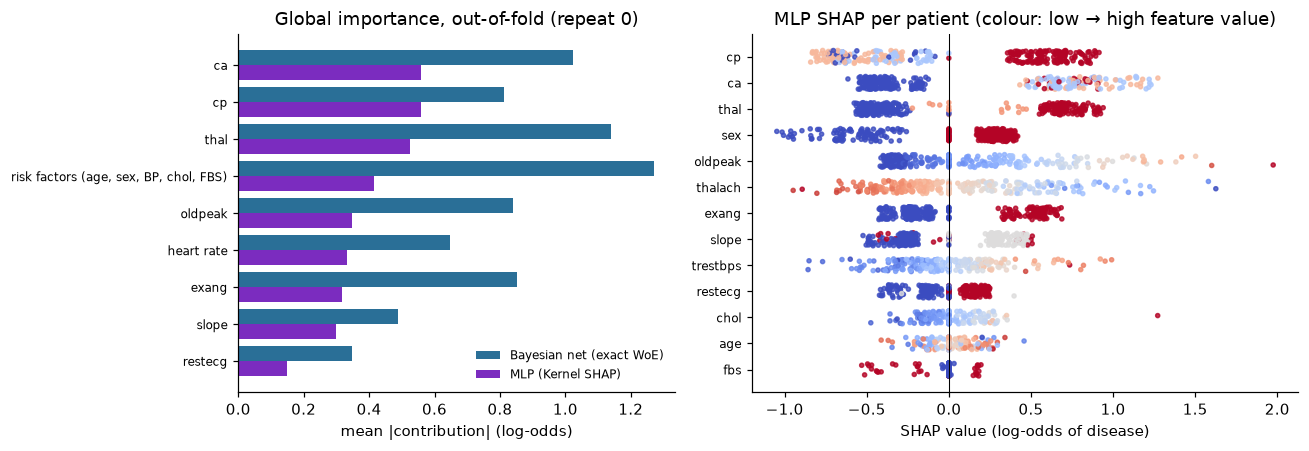

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
o = imp.sort_values("MLP |SHAP|").index; yv = np.arange(len(o))
ax[0].barh(yv + .2, imp.loc[o, "BN |weight of evidence|"], .4, color=BLUE, label="Bayesian net (exact WoE)")
ax[0].barh(yv - .2, imp.loc[o, "MLP |SHAP|"], .4, color=PURPLE, label="MLP (Kernel SHAP)")
ax[0].set_yticks(yv); ax[0].set_yticklabels(o, fontsize=8); ax[0].set(xlabel="mean |contribution| (log-odds)", title="Global importance, out-of-fold (repeat 0)"); ax[0].legend(frameon=False, fontsize=8)
# beeswarm-style summary for the MLP
order = SH.abs().mean().sort_values().index
for i, c in enumerate(order):
    v = Xr[c].astype(float); z = (v - v.min()) / (v.max() - v.min() + 1e-9)
    jit = np.random.default_rng(i).uniform(-.25, .25, len(SH))
    ax[1].scatter(SH[c], i + jit, c=z, cmap="coolwarm", s=7, alpha=.8)
ax[1].set_yticks(range(len(order))); ax[1].set_yticklabels(order, fontsize=8); ax[1].axvline(0, color="k", lw=.7)
ax[1].set(xlabel="SHAP value (log-odds of disease)", title="MLP SHAP per patient (colour: low → high feature value)")
save("fig_p2_shap_vs_bn.png")

### 9.1 Does the MLP actually use interactions?
If the MLP were learning the age × heart-rate (or other) interactions the brief suspects, the SHAP value of a variable would depend on the value of *another* variable at a fixed level of the first. The dependence plots below show the SHAP value of max heart rate and ST depression against their own values, coloured by age. Vertical spread at a fixed x-value that tracks colour would indicate an interaction; a tight monotone band means the network behaves almost additively for that variable.

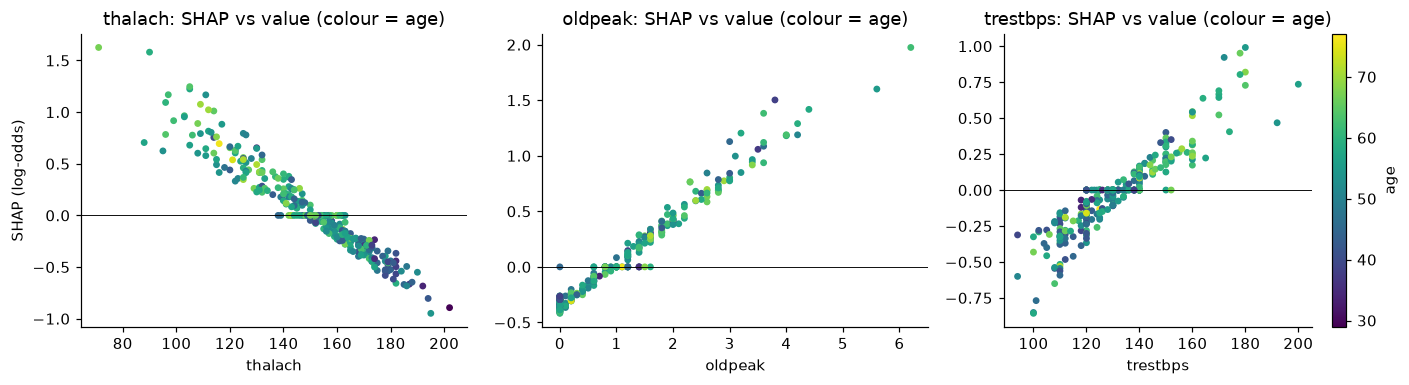

,SHAP sd,sd not explained by own value,share
variable,,,
age,0.105,0.103,0.973
trestbps,0.271,0.109,0.163
chol,0.138,0.074,0.286
thalach,0.435,0.116,0.071
oldpeak,0.456,0.070,0.023


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, c in zip(ax, ["thalach", "oldpeak", "trestbps"]):
    sc = a.scatter(Xr[c], SH[c], c=Xr["age"], cmap="viridis", s=12); a.axhline(0, color="k", lw=.6)
    a.set(xlabel=c, ylabel="SHAP (log-odds)" if c == "thalach" else "", title=f"{c}: SHAP vs value (colour = age)")
plt.colorbar(sc, ax=ax[-1], label="age"); save("fig_p2_shap_dependence.png")
# a simple numeric summary: how much SHAP variance for each numeric variable is NOT explained by its own value (a smooth fit)
rows = []
for c in NUM:
    x = Xr[c].astype(float); ok = x.notna(); coef = np.polyfit(x[ok], SH.loc[ok, c], 3); resid = SH.loc[ok, c] - np.polyval(coef, x[ok])
    rows.append({"variable": c, "SHAP sd": SH[c].std(), "sd not explained by own value": resid.std(), "share": resid.var() / SH[c].var()})
display(pd.DataFrame(rows).set_index("variable").round(3))

### 9.2 Two patients, two explanations
The same two patients highlighted in Phase 1 §8 (the most confident correct BN prediction for a diseased patient and for a healthy patient), now explained by both models.

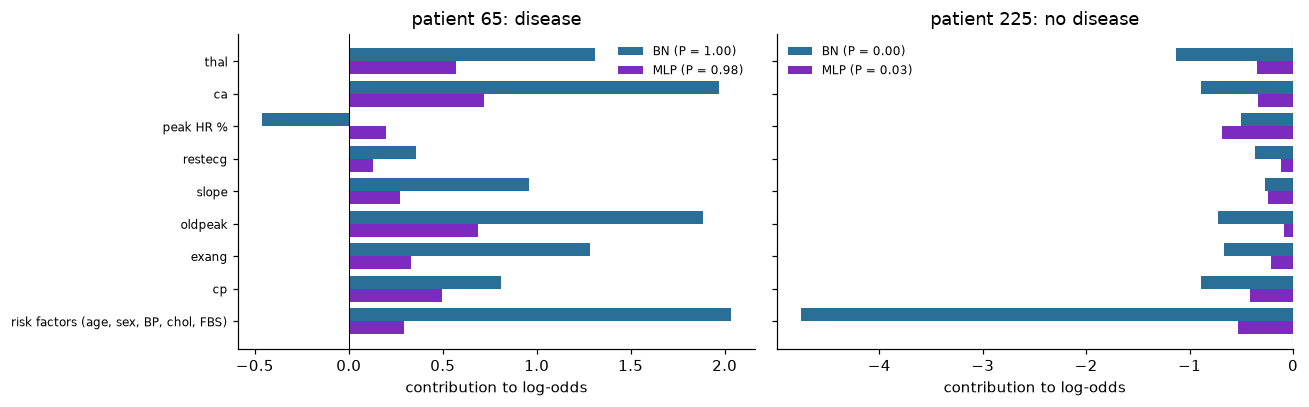

In [15]:
ex = [int(np.argmax(np.where(y == 1, results["Bayesian net"]["oof"][0], -1))), int(np.argmin(np.where(y == 0, results["Bayesian net"]["oof"][0], 2)))]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
cols = list(W.columns); yv = np.arange(len(cols))
for a, i in zip(ax, ex):
    a.barh(yv + .2, W.iloc[i][cols], .4, color=BLUE, label=f"BN (P = {results['Bayesian net']['oof'][0, i]:.2f})")
    a.barh(yv - .2, mlp_grouped.iloc[i][cols], .4, color=PURPLE, label=f"MLP (P = {results['MLP']['oof'][0, i]:.2f})")
    a.axvline(0, color="k", lw=.7); a.set(title=f"patient {i}: {'disease' if y[i] else 'no disease'}", xlabel="contribution to log-odds"); a.legend(frameon=False, fontsize=8)
ax[0].set_yticks(yv); ax[0].set_yticklabels(cols, fontsize=8); save("fig_p2_two_patients.png")

## 10. Compute cost
Wall-clock time to fit and predict one outer fold, measured on this machine (single CPU thread for the MLP). The MLP time includes the nested inner tuning (12 configurations × 3 inner folds) and the 5-seed final fit.

In [16]:
tr, te = splits[0]; cost = []
for name, mk, X in [("Naive Bayes", lambda: BNClassifier(NB_EDGES), Xd), ("Bayesian net", lambda: BNClassifier(BN_EDGES), Xd),
                    ("LogReg (cont.)", lambda: LogReg("continuous"), Xr), ("Random forest", lambda: Forest(seed=0), Xr),
                    ("MLP (fixed config, no tuning)", lambda: MLP(tune=False, config=mlp_runs["MLP"]["models"][0].config, epochs=mlp_runs["MLP"]["models"][0].epochs), Xr)]:
    t = time.time(); mk().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te]); cost.append({"model": name, "seconds per fold": time.time() - t})
cost.append({"model": "MLP (nested tuning, as evaluated)", "seconds per fold": mlp_runs["MLP"]["seconds"] / len(splits)})
cost = pd.DataFrame(cost).set_index("model"); cost["parameters"] = ["CPD entries", "CPD entries", "29", "300 trees", str(mlp_runs["MLP"]["models"][0].n_params()), str(mlp_runs["MLP"]["models"][0].n_params()) + " (×5 seeds)"]
cost.to_csv(RES / "phase2_cost.csv"); display(cost.round(3))

,seconds per fold,parameters
model,,
Naive Bayes,0.041,CPD entries
Bayesian net,0.038,CPD entries
LogReg (cont.),0.009,29
Random forest,0.149,300 trees
"MLP (fixed config, no tuning)",0.068,481
"MLP (nested tuning, as evaluated)",2.600,481 (×5 seeds)


## 11. Findings, answer to the gap, and limitations
The cell below prints the headline numbers that the conclusions rest on, so the text cannot drift from the results.

In [17]:
r = lambda m, k: Mi.loc[m, k]
pc = PC.set_index(["A", "B", "metric"])
print(f"ROC AUC   MLP {r('MLP','ROC AUC'):.3f} | BN {r('Bayesian net','ROC AUC'):.3f} | NB {r('Naive Bayes','ROC AUC'):.3f} | LogReg {r('LogReg (cont.)','ROC AUC'):.3f} | RF {r('Random forest','ROC AUC'):.3f}")
print(f"Brier     MLP {r('MLP','Brier'):.3f} | BN {r('Bayesian net','Brier'):.3f} | NB {r('Naive Bayes','Brier'):.3f} | LogReg {r('LogReg (cont.)','Brier'):.3f}")
print(f"Cal slope MLP {r('MLP','Cal. slope'):.2f} | BN {r('Bayesian net','Cal. slope'):.2f} | NB {r('Naive Bayes','Cal. slope'):.2f} | LogReg {r('LogReg (cont.)','Cal. slope'):.2f}")
for a, b in pairs:
    x = pc.loc[(a, b, "ROC AUC")]; z = pc.loc[(a, b, "Brier")]
    print(f"{a} − {b}: ΔAUC {x['mean diff (A-B)']:+.3f} [{x['lo']:+.3f}, {x['hi']:+.3f}] p_corr={x['corrected p']:.2f} | ΔBrier {z['mean diff (A-B)']:+.3f} [{z['lo']:+.3f}, {z['hi']:+.3f}]")

ROC AUC   MLP 0.911 | BN 0.896 | NB 0.908 | LogReg 0.911 | RF 0.908
Brier     MLP 0.117 | BN 0.139 | NB 0.126 | LogReg 0.116
Cal slope MLP 1.00 | BN 0.49 | NB 0.51 | LogReg 0.98
MLP − Bayesian net: ΔAUC +0.015 [-0.001, +0.031] p_corr=0.14 | ΔBrier -0.022 [-0.036, -0.007]
MLP − Naive Bayes: ΔAUC +0.003 [-0.005, +0.014] p_corr=0.41 | ΔBrier -0.009 [-0.021, +0.001]
MLP − LogReg (cont.): ΔAUC +0.000 [-0.005, +0.007] p_corr=0.83 | ΔBrier +0.001 [-0.004, +0.005]
MLP − Random forest: ΔAUC +0.003 [-0.007, +0.015] p_corr=0.47 | ΔBrier -0.008 [-0.016, +0.001]
MLP (binned) − Bayesian net: ΔAUC +0.015 [-0.002, +0.030] p_corr=0.11 | ΔBrier -0.023 [-0.036, -0.008]
MLP − MLP (binned): ΔAUC +0.000 [-0.009, +0.009] p_corr=0.81 | ΔBrier +0.001 [-0.005, +0.008]


### 11.1 Interpretation (read together with the printed numbers above)
1. **Ranking.** The MLP ranks patients as well as every Phase 1 model (OOF ROC AUC 0.911 vs 0.896 BN, 0.908 NB, 0.911 logistic regression, 0.908 random forest). Every paired AUC interval includes zero (MLP − BN: +0.015 [−0.001, +0.031], corrected p = 0.14). We do **not** claim equivalence, but there is no evidence of a ranking gain from learned interactions.
2. **Probabilities — this is where the gap shows.** The BN and Naive Bayes are over-confident: calibration slope 0.49 and 0.51, with about 60% of their predictions below 0.05 or above 0.95, and the BN is confidently wrong (P > 0.9 for a healthy patient or P < 0.1 for a diseased one) for 21 patients versus 5 for the MLP. The regularised MLP, tuned on log loss, has calibration slope 1.00, ECE 0.044 and a Brier score 0.022 lower than the BN (95% interval [−0.036, −0.007], excluding zero). The improvement over the BN is about **probability quality**, not ranking.
3. **Where does the BN's problem come from?** *MLP (binned)* sees exactly the BN's binned inputs and is just as well calibrated (slope 1.07, Brier 0.115; Brier vs BN −0.023 [−0.036, −0.008]). So the BN's over-confidence is **not caused by the bins**; it is consistent with the hand-specified independence structure and count-based CPDs (correlated findings multiplied as if independent). *MLP − MLP (binned)* shows that discretisation cost nothing measurable here (ΔAUC +0.000 [−0.009, +0.009]).
4. **Nonlinear interactions.** MLP − LogReg (cont.) has identical inputs, and the difference is essentially zero (ΔAUC +0.000 [−0.005, +0.007], ΔBrier +0.001). Nested tuning chose a single small hidden layer in 22 of 25 folds with early stopping at a median of 73 epochs, and the SHAP dependence plots are nearly monotone in each variable's own value (93–98% of the SHAP variance of heart rate and ST depression is explained by their own value). **At n = 303 the data do not support detectable nonlinear interactions beyond an additive logistic model.** The brief's hypothesised gap is real for *calibration*, not demonstrated for *interactions*.
5. **Explanations.** For the MLP, `cp`, `ca` and `thal` carry the most weight, followed by ST depression, heart rate and exercise angina; for the BN, `thal`, `ca` and the risk-factor term lead. The rank correlation over the 8 shared findings is 0.64: broadly the same story. The BN's contributions are roughly twice as large in magnitude, which is the over-confidence of §5 seen from the inside. The BN's weights are exact by construction; the MLP's SHAP values approximate a black box, but both are on the same log-odds scale.
6. **Without `ca`/`thal`.** Every model loses about 0.04–0.05 AUC; the MLP (0.868) stays level with logistic regression (0.872) and stays calibrated (slope 0.97), while the BN remains over-confident (slope 0.49).
7. **Cost.** Each tuned MLP fit takes about 2.6 s per fold (mostly nested tuning) versus under 0.15 s for every classical model; one fixed-configuration MLP fit takes 0.07 s.

### 11.2 Limitations
- 303 historical, single-centre rows, mostly male; no external validation; no verifiable patient IDs, so row independence is assumed.
- The target is *existing* angiographic disease, not future risk; inputs include exercise-test and work-up findings.
- The Phase 1 graph, bins and classical hyper-parameters were not tuned under nested CV; the MLP was. This gives the MLP a fair, not an unfair, budget, but the asymmetry is noted.
- The 25 splits were already seen in Phase 1; they are not a new untouched test set. Bootstrap intervals condition on fitted OOF predictions and omit training variability; repeated-CV predictions are dependent; corrected *t*-tests are exploratory without multiplicity control.
- Calibration slope and ECE are noisy at this sample size. Kernel SHAP is a sampling approximation with an assumed background, and it explains model behaviour, not causation.
- Neural-network results depend on random initialisation; we average 5 seeds per fit and fix all seeds, but small differences are expected across hardware and library versions.
- **Not for clinical use.** No predicted probability here is a medical recommendation.